# Film spaces in 2D: four projections, nine spaces

Each film can be described as a point in a high-dimensional space: the embedding of its screenplay, of its plot
summary, of its Wikipedia plot section, of its audience reviews, its scores on the Tag Genome's 1,084 tags and 22
genres, the people who made it, or the sentiment arc of its script. To look at such a space we have to squash it to two dimensions, and the method we choose decides what
survives. This notebook draws every space four ways (PCA, Isomap, t-SNE, UMAP) and scores each map against the full
space, so that a pattern on a map can be checked before anyone reads it as a finding. The follow-up checks (how
stable the maps are across seeds, whether the spaces agree, clusters, release year, and a sheet for checking
neighbours by hand) are in `notebooks/embedding_map_checks.ipynb`, which reads the maps this notebook saves.

**Takeaway.** t-SNE keeps each film's neighbours best and PCA keeps large distances best. In eight of the nine
spaces, films near each other have more similar profit than chance, and every 2D map shows less of that than the
full space holds, so a map without a visible profit pattern is no evidence against one. Taking out budget, year and
genre, or the reception tags, barely changes this. Sentiment arcs are the exception: neighbours there share no
profit at all. Section 10 has the numbers.

The projection code and the three scores are in `analysis/projections.py`:

- **neighbours kept**: the share of each film's 10 nearest films in the full space that are also among its 10
  nearest on the map. Chance is about 10 / number of films.
- **distance rank**: the Spearman correlation between pairwise distances in the full space and on the map, over
  3,000 random films. High means far films stay far.
- **profit smoothness**: the Spearman correlation between a film's ln(gross / budget) and the mean of its 10 nearest
  films. It's given on each map and in the full space, with a shuffle null (multiples permuted between films). A map
  value well above the full-space one means the map makes profit look more clustered than the space really is.
- **net smoothness**: the same, on the multiple net of budget, year and genre (the residual of a linear fit, see
  `sample()` in analysis/film_spaces.py). Cheap horror films sit together and horror returns more per dollar, so raw smoothness partly
  restates genre and budget. Net smoothness asks whether neighbours share profit beyond that. It's the narrower
  question, and it sits next to the raw score rather than replacing it.

The top row of each figure is coloured by ln(gross / budget), the bottom row by the film's primary IMDb genre (the
first of Horror, Sci-Fi, Thriller, Adventure, Action, Comedy, Drama it has, else Other). The genre row shows what
each map organises films by. Axes on t-SNE and UMAP maps have no units, so they're hidden on every map.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from analysis.film_spaces import FEATURES as F, SEED, cast_crew, load_spaces, reception_mask, sample
from analysis.projections import compare

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

d = sample()   # the clean sample with ln(multiple) and the net multiple, see analysis/film_spaces.py
S = load_spaces(d)
print(f"clean sample: {len(d):,} films; budget, year and {d.attrs['genre_dummies']} genre dummies explain "
      f"R2 = {d.attrs['net_r2']:.3f} of ln(multiple)")
print(pd.Series({k: f"{len(v[0]):,} films x {v[1].shape[1]:,}" for k, v in S.items()}).to_string())

results, coords = [], []

def run(name):
    """Draw and score the four maps of one space, and keep the coordinates for the explorer."""
    ids, V = S[name]
    f = d.loc[ids]
    out, maps = compare(V, f.log_mult.to_numpy(), f.primary_genre.to_numpy(), name,
                        y_net=f.log_mult_net.to_numpy(), seed=SEED)
    results.append(out)
    for method, Y in maps.items():
        coords.append(pd.DataFrame({"space": name, "method": method, "tconst": ids, "x": Y[:, 0], "y": Y[:, 1],
                                    "title": f.title.to_numpy(), "year": f.year.to_numpy(),
                                    "primary_genre": f.primary_genre.to_numpy(), "log_mult": f.log_mult.to_numpy(),
                                    "log_mult_net": f.log_mult_net.to_numpy()}))

clean sample: 6,443 films; budget, year and 20 genre dummies explain R2 = 0.072 of ln(multiple)
Screenplays                 1,630 films x 384
MovieSum summaries          1,625 films x 384
Wikipedia plots             6,399 films x 384
Reviews                     5,405 films x 384
Tag relevance             4,271 films x 1,084
Tags without reception      4,271 films x 978
Genre shares                 4,271 films x 22
Cast and crew               6,414 films x 100
Sentiment arcs               1,548 films x 40


The sample is 6,443 films rather than the 6,413 the 2026-11-15 rule gives. The data folder these cells ran on has an
infobox table from before that day's rentals flag, so about 30 films whose gross is cited as rentals are still in.

## 1. Screenplays (MovieSum)

`features/text_vectors/screenplays_clean.npy`, from `analysis/embeddings/s02_embed.py`: the all-MiniLM-L6-v2 embedding of each cleaned script's 180-word passages
(speaker labels and character names replaced), averaged and normalised. It keeps topic and setting, not structure
or quality.

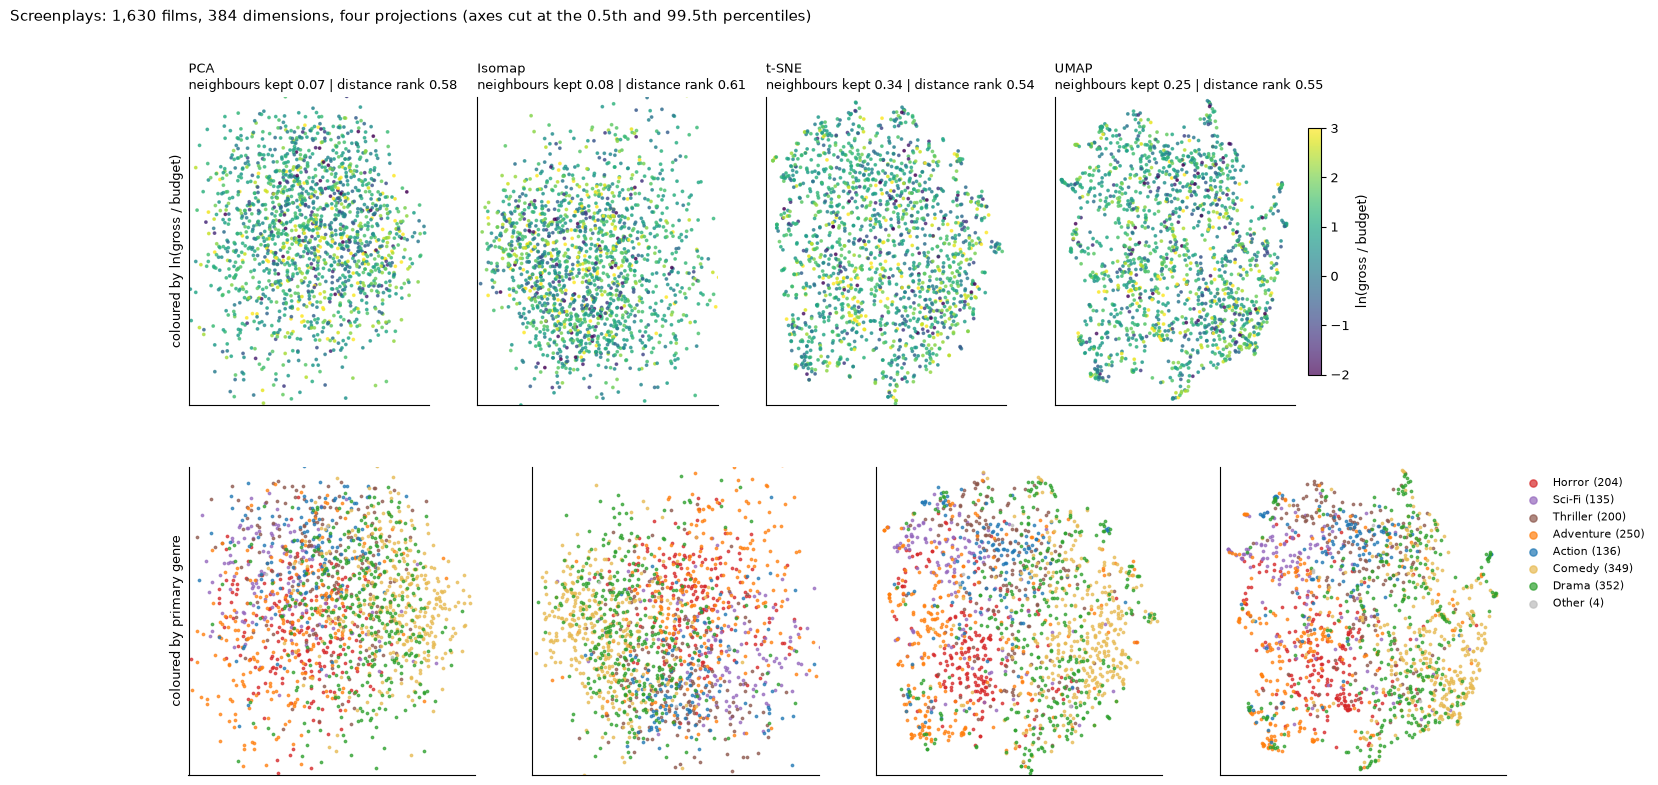

chance level for neighbours kept: 0.0061; profit smoothness in the full space: 0.151 (shuffled outcomes, 95% range -0.059 to +0.054)
net of budget, year and genre: full space 0.130 (shuffled, 95% range -0.051 to +0.050)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.068          0.575              0.049           0.024
Isomap            0.079          0.611              0.011           0.028
t-SNE             0.338          0.537              0.130           0.098
UMAP              0.249          0.546              0.105           0.077


In [2]:
run("Screenplays")

## 2. Plot summaries (MovieSum)

`features/text_vectors/summaries_clean.npy`, same pipeline as the screenplays: MovieSum's summary of each film,
which is a few hundred words describing the plot. Same films as the screenplays, give or take five.

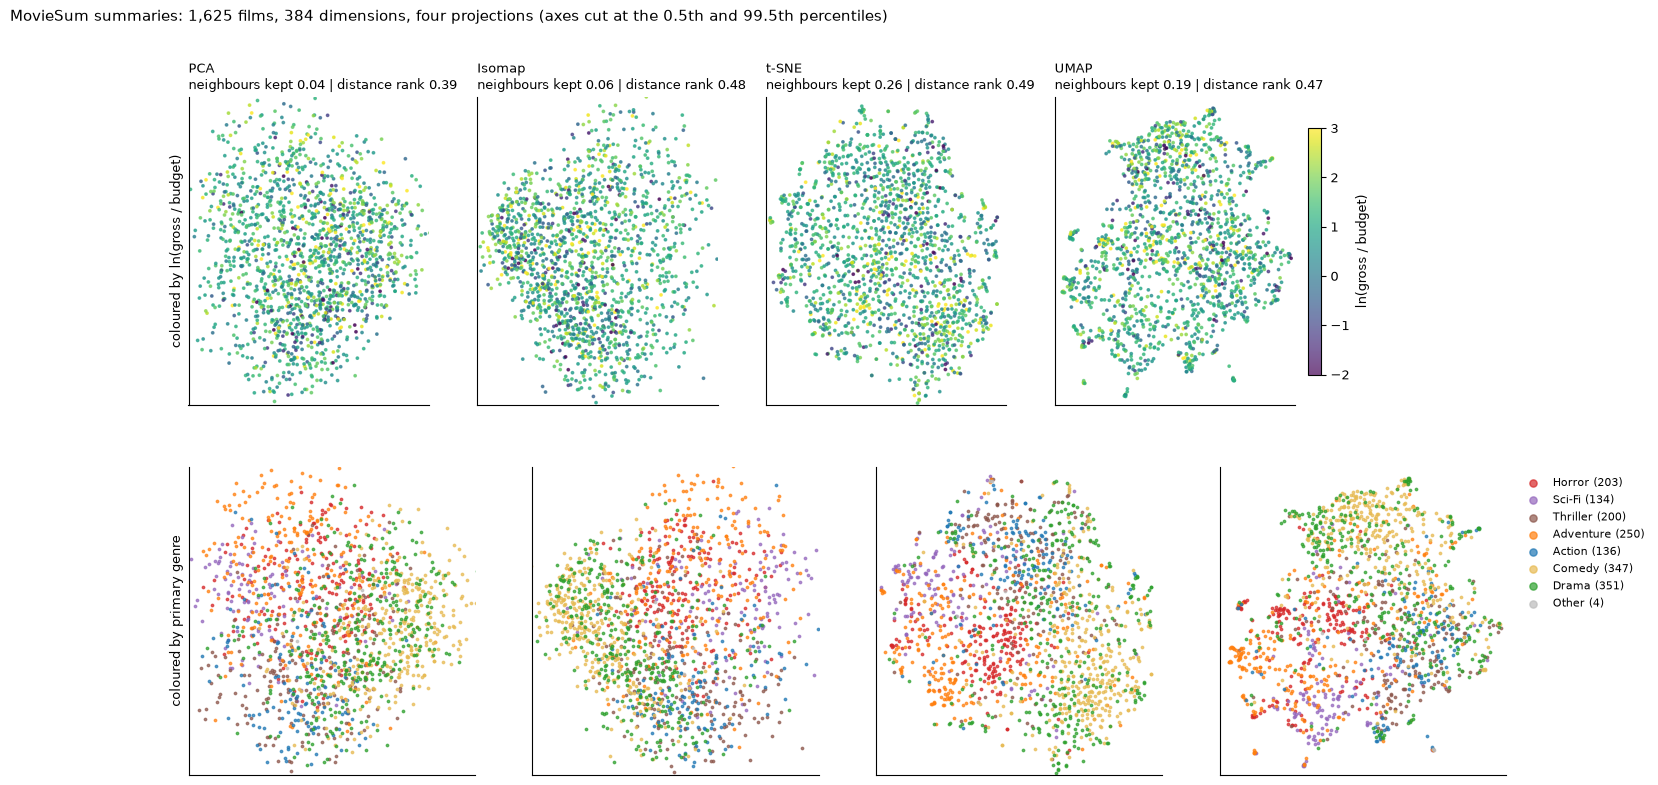

chance level for neighbours kept: 0.0062; profit smoothness in the full space: 0.143 (shuffled outcomes, 95% range -0.057 to +0.056)
net of budget, year and genre: full space 0.129 (shuffled, 95% range -0.064 to +0.048)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.042          0.395             -0.047          -0.018
Isomap            0.056          0.483              0.041           0.023
t-SNE             0.256          0.488              0.107           0.110
UMAP              0.193          0.468              0.135           0.121


In [3]:
run("MovieSum summaries")

## 3. Wikipedia plot sections

`features/plot_vectors.npy`, from `scripts/reviews/plot_embeddings.py`: the first Plot / Synopsis / Premise section of each film's Wikipedia article, wiki markup stripped, embedded with the same
model in 180-word passages and averaged. It covers almost every clean film, so this is the widest text space. Plot
sections are written after release but don't say how the film did.

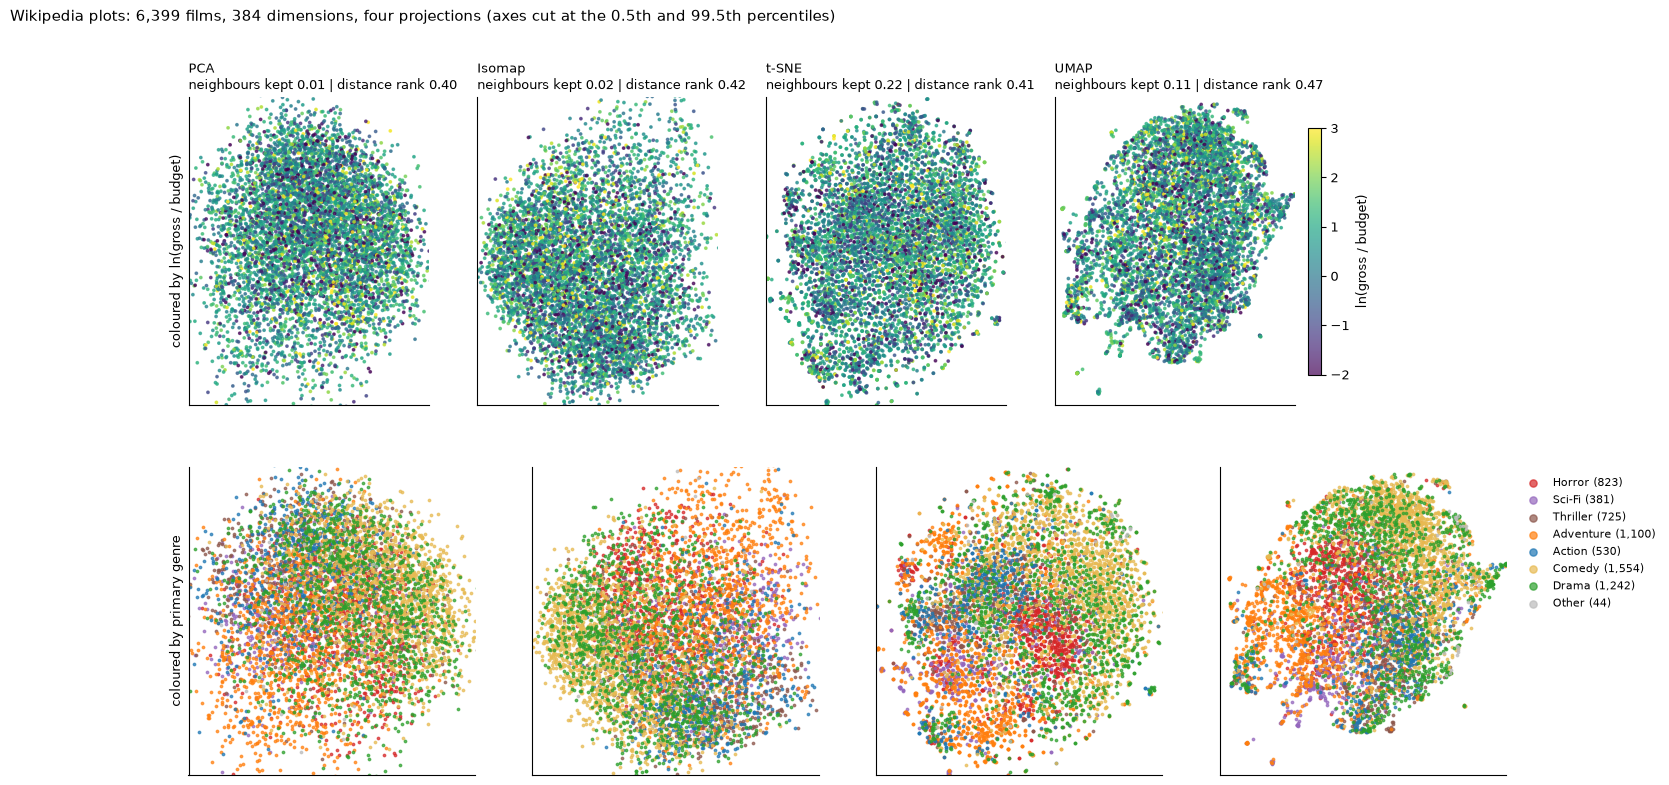

chance level for neighbours kept: 0.0016; profit smoothness in the full space: 0.168 (shuffled outcomes, 95% range -0.028 to +0.029)
net of budget, year and genre: full space 0.145 (shuffled, 95% range -0.032 to +0.030)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.011          0.403             -0.009          -0.011
Isomap            0.016          0.422              0.004          -0.010
t-SNE             0.225          0.413              0.113           0.091
UMAP              0.108          0.469              0.082           0.061


In [4]:
run("Wikipedia plots")

## 4. Audience reviews (MovieLens Tag Genome)

`features/text_vectors/reviews_clean.npy`: up to 30 English reviews per film, embedded and averaged. Reviews are
written after release and some mention the box office, so profit structure here is partly the outcome leaking in.

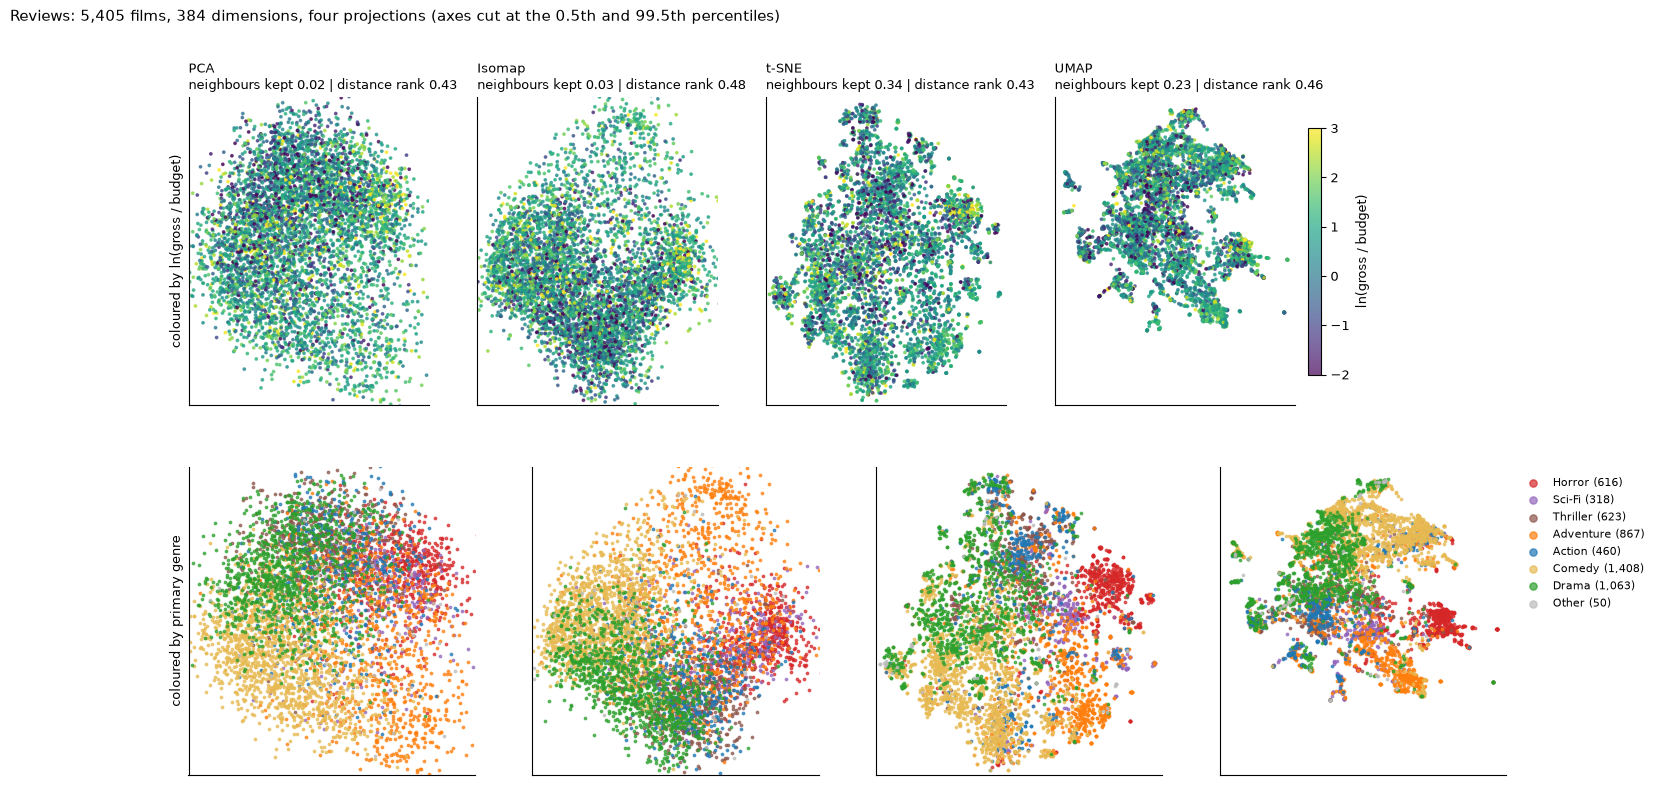

chance level for neighbours kept: 0.0019; profit smoothness in the full space: 0.309 (shuffled outcomes, 95% range -0.031 to +0.026)
net of budget, year and genre: full space 0.270 (shuffled, 95% range -0.041 to +0.027)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.023          0.428              0.107           0.042
Isomap            0.033          0.478              0.082           0.012
t-SNE             0.341          0.434              0.248           0.202
UMAP              0.231          0.463              0.185           0.148


In [5]:
run("Reviews")

## 5. How much each film fits each tag (Tag Genome relevance)

`features/tag_relevance.npy`, from `scripts/reviews/tag_shares.py`: for each film, the Tag Genome's 0-to-1
relevance of all 1,084 tags (mean of the TagDL and glmer scores). This is a space of categories rather than text:
"dark", "heist", "visually appealing", "oscar (best picture)". The scores are predicted from what viewers tagged,
rated and wrote after release, so tags such as "boring" or "oscar (best picture)" hold the film's reception. The
Tag Genome covers only films up to 2014.

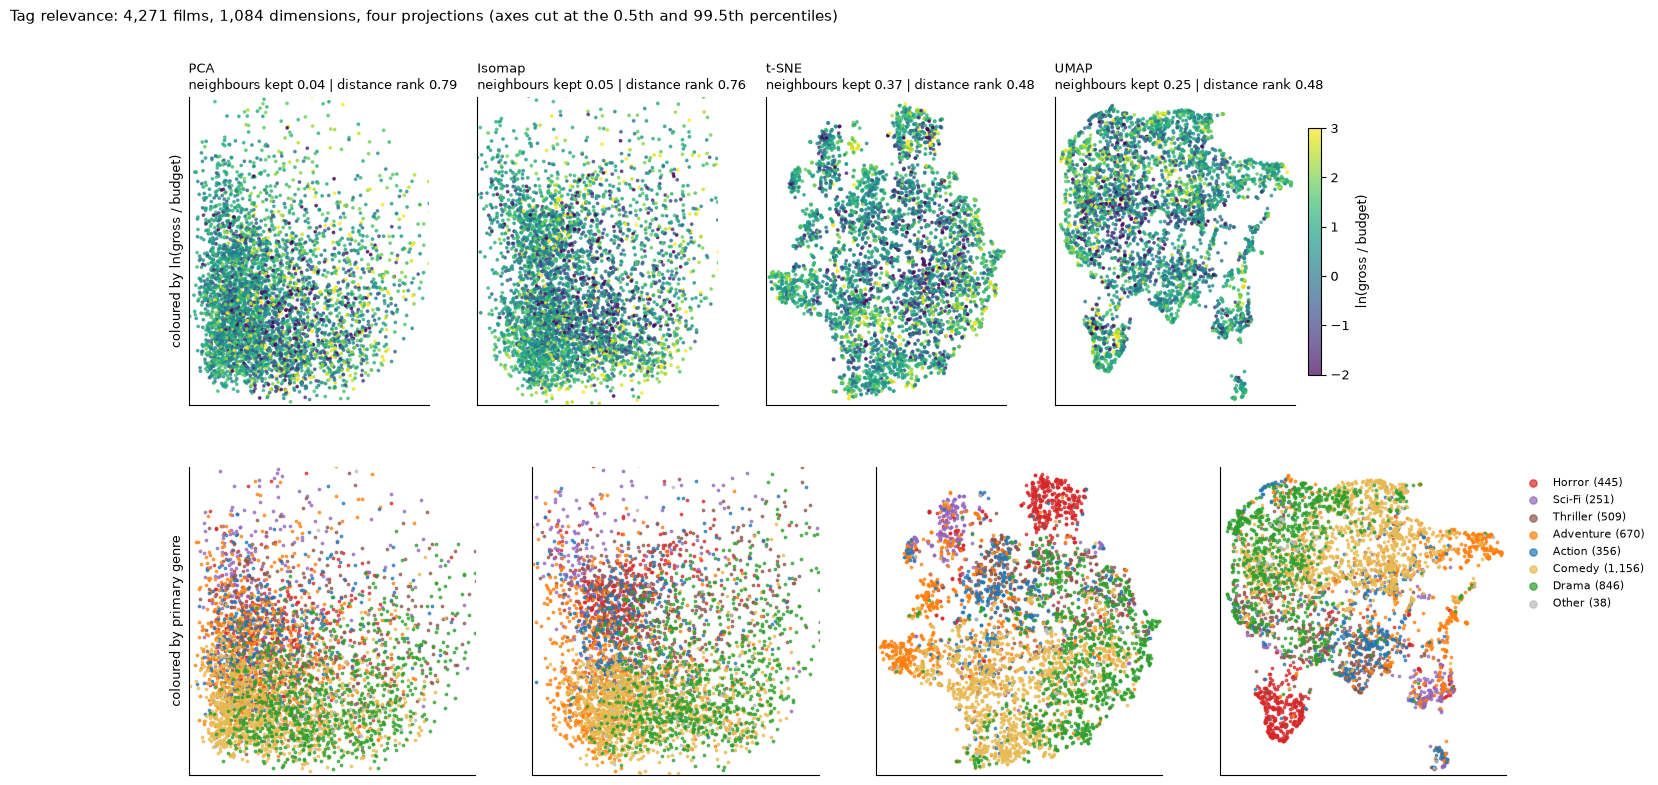

chance level for neighbours kept: 0.0023; profit smoothness in the full space: 0.496 (shuffled outcomes, 95% range -0.038 to +0.033)
net of budget, year and genre: full space 0.497 (shuffled, 95% range -0.033 to +0.035)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.038          0.789              0.086           0.122
Isomap            0.054          0.758              0.195           0.197
t-SNE             0.367          0.477              0.385           0.381
UMAP              0.247          0.483              0.324           0.314


In [6]:
run("Tag relevance")

## 5b. Tags without reception

The same space with the tags that hold the film's reception taken out: tags that judge quality ("great acting",
"boring", "overrated"), record an award or a best-of list ("oscar (best picture)", "imdb top 250", "afi 100") or mark
cult status. The list below was picked by hand from the tag names, before looking at any result for it. Tags of
content and tone ("dark", "heist", "funny", "scary") stay, although viewers' tone words carry some judgement too.

dropping 106 of 1,084 tags, keeping 978
dropped: afi 100, afi 100 (movie quotes), amazing cinematography, amazing photography, awesome, awesome soundtrack, bad, bad acting, bad cgi, bad ending, bad plot, bad science, bad script, bad sequel, beautifully filmed, best war films, better than expected, better than the american version, book was better, boring, boring!, breathtaking, brilliant, classic, crappy sequel, criterion, cult, cult classic, cult film, disappointing, dumb, dumb but funny, excellent, excellent script, exceptional acting, funniest movies, golden palm, good, good acting, good action, good dialogue, good music, good romantic comedies, good sequel, good soundtrack, good story, great, great acting, great cinematography, great dialogue, great ending, great movie, great music, great soundtrack, guilty pleasure, highly quotable, horrible, idiotic, imdb top 250, lame, masterpiece, movielens top pick, no plot, not as good as the first, not funny, notable soundtrack, oscar, oscar

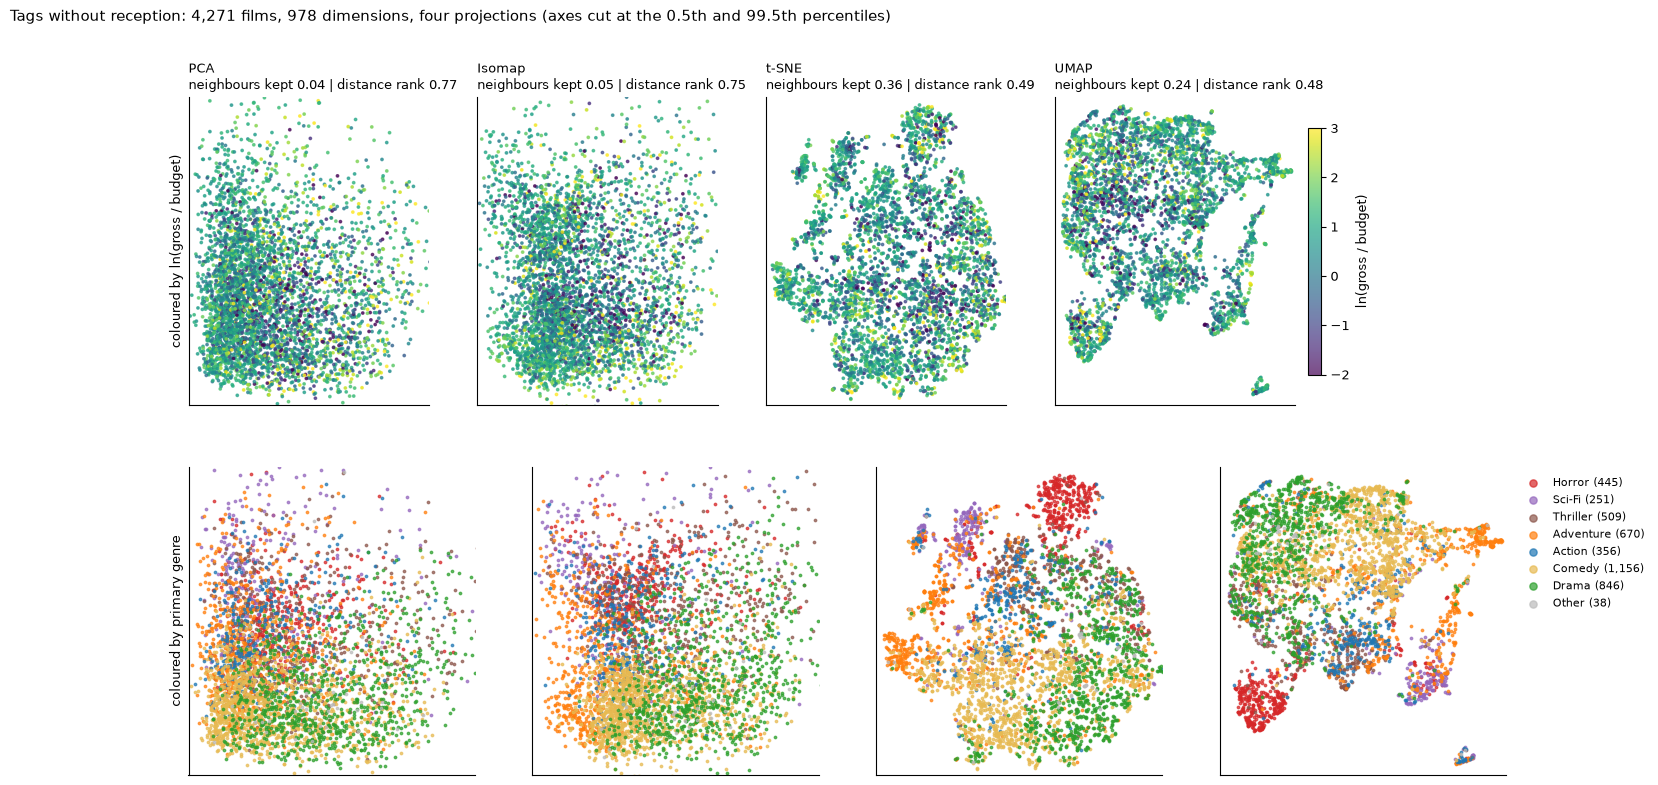

chance level for neighbours kept: 0.0023; profit smoothness in the full space: 0.485 (shuffled outcomes, 95% range -0.037 to +0.037)
net of budget, year and genre: full space 0.489 (shuffled, 95% range -0.035 to +0.030)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.036          0.773              0.096           0.148
Isomap            0.055          0.750              0.185           0.184
t-SNE             0.362          0.491              0.354           0.356
UMAP              0.241          0.478              0.272           0.287


In [7]:
tags = pd.read_csv(F / "tag_relevance_tags.csv").tag
drop = reception_mask(tags)
print(f"dropping {drop.sum()} of {len(tags):,} tags, keeping {(~drop).sum():,}")
print("dropped:", ", ".join(tags[drop]))
run("Tags without reception")

## 6. How much each film is each genre (genre shares)

`features/genre_shares.csv`, from the same script: the relevance of the tag that names each of IMDb's 22 genres,
squared and divided by the film's total, so each film's shares sum to 1 (a film can be 0.6 action, 0.3 sci-fi,
0.1 comedy). With 22 dimensions there is little to squash, so this is the easiest space to map. The bottom row's
colours are IMDb's own genre labels, which the shares were not fitted to.

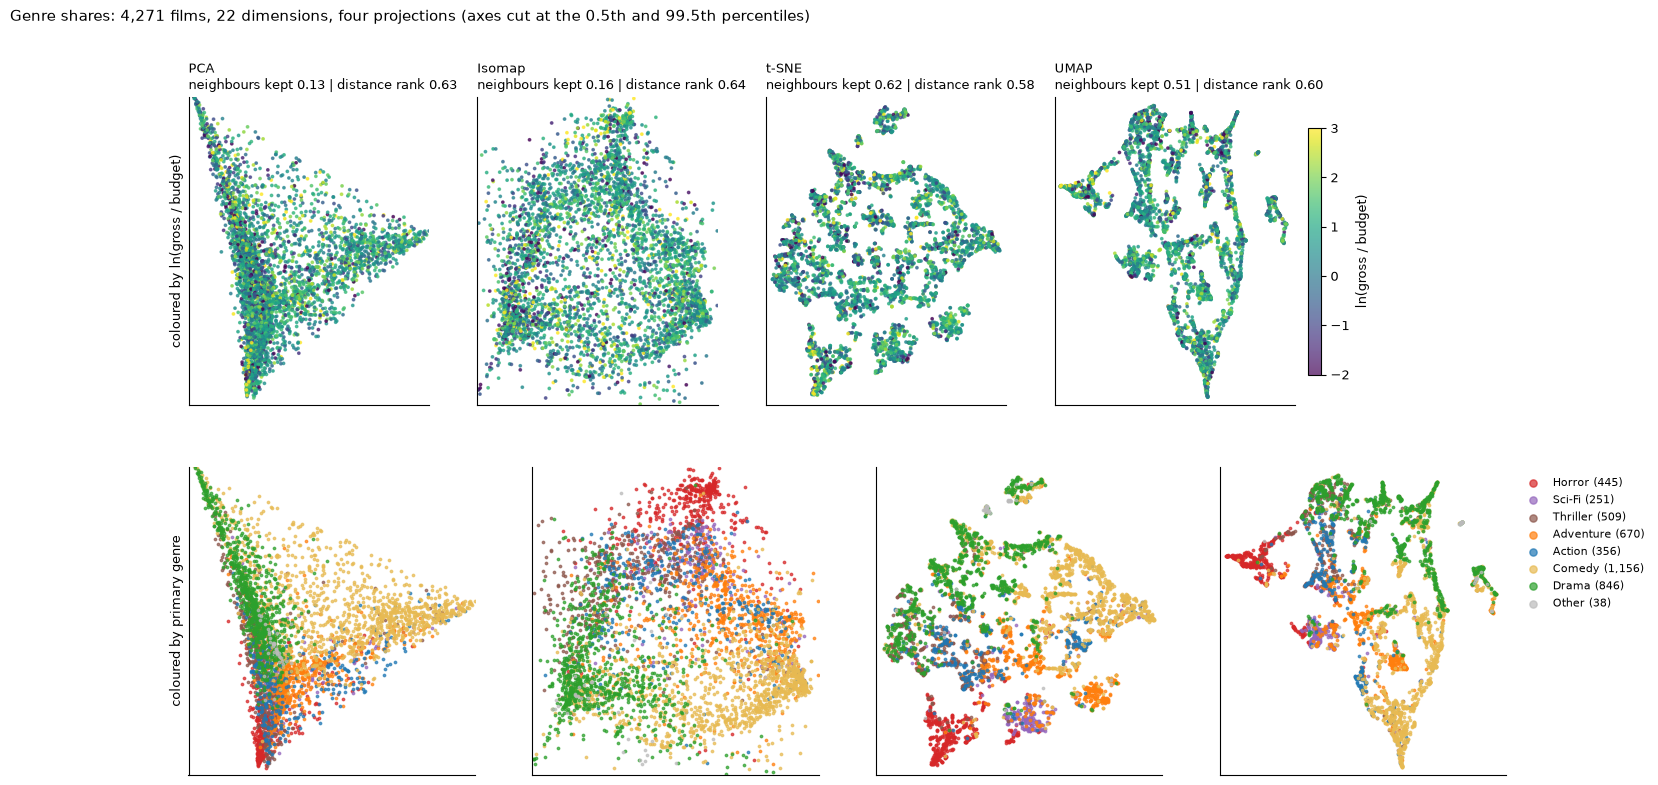

chance level for neighbours kept: 0.0023; profit smoothness in the full space: 0.222 (shuffled outcomes, 95% range -0.039 to +0.032)
net of budget, year and genre: full space 0.210 (shuffled, 95% range -0.037 to +0.036)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.134          0.628              0.071           0.077
Isomap            0.159          0.643              0.082           0.072
t-SNE             0.619          0.579              0.189           0.182
UMAP              0.508          0.597              0.144           0.133


In [8]:
run("Genre shares")

## 7. Who made the film (cast and crew)

Each film as the people who made it: IMDb's principal credits (actors, director, writers, producers, editor,
composer, cinematographer) as a film x person matrix over the clean sample, TF-IDF weighted so that someone on many
films counts less, reduced to 100 dimensions (`cast_crew()` in analysis/film_spaces.py). Only people on 2+ clean
films are kept, since someone on one film makes no two films alike. This is the one space built from facts known
before release, and no outcome enters it. But the reduction is fitted on all films at once, so a film's neighbours
can be later films, and neighbours that share profit may share it because a successful team was hired again.

6,414 films linked by 16,072 people with 2+ clean films (88,998 credits)


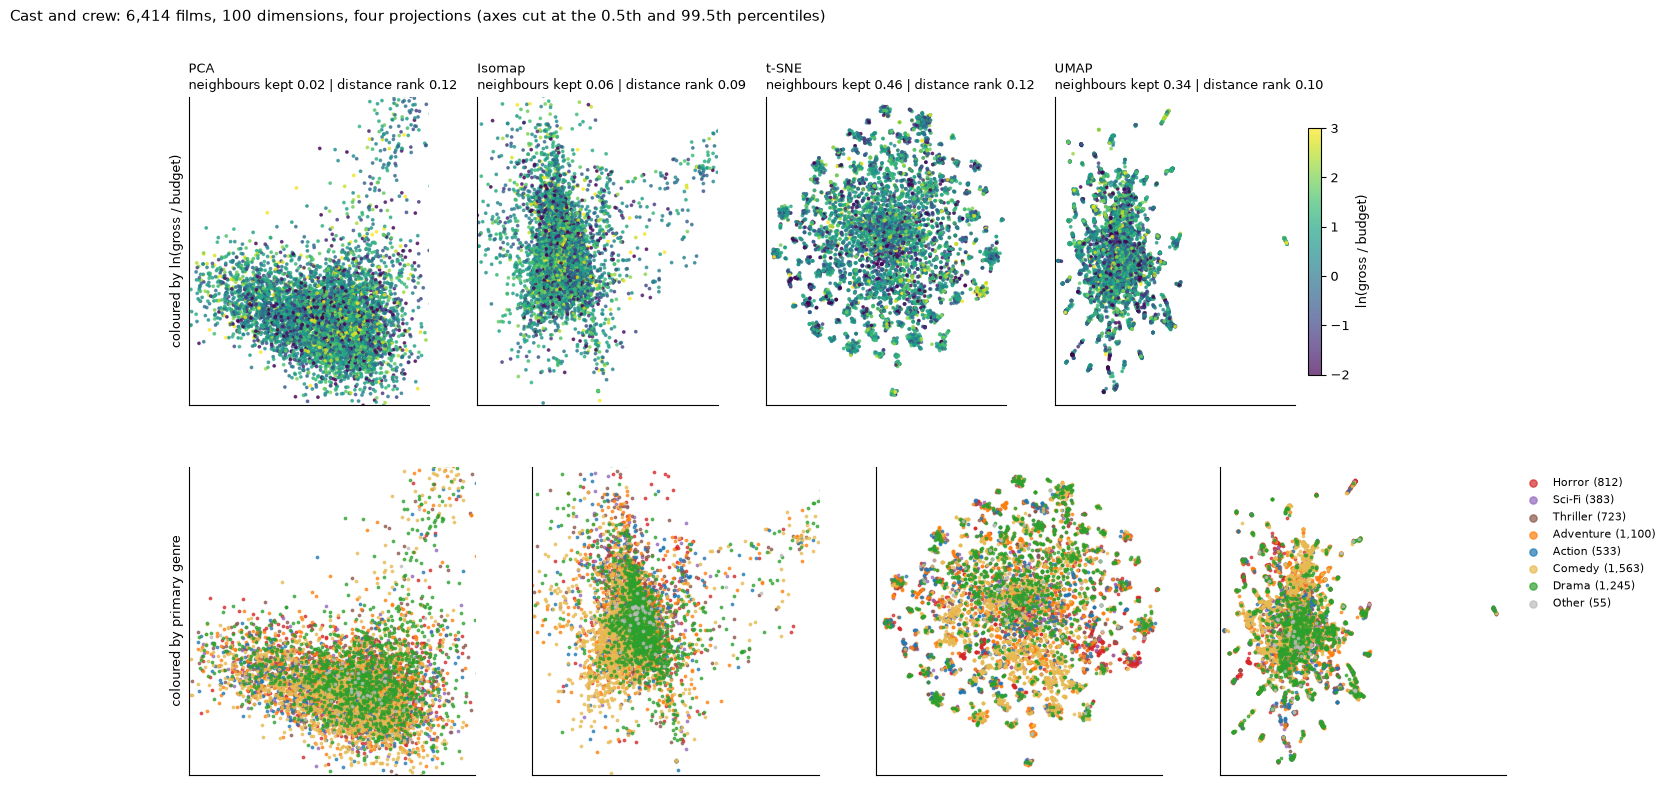

chance level for neighbours kept: 0.0016; profit smoothness in the full space: 0.229 (shuffled outcomes, 95% range -0.027 to +0.024)
net of budget, year and genre: full space 0.214 (shuffled, 95% range -0.028 to +0.036)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.022          0.119              0.037           0.047
Isomap            0.060          0.093              0.072           0.049
t-SNE             0.460          0.118              0.190           0.177
UMAP              0.337          0.100              0.166           0.149


In [9]:
films, _, info = cast_crew(d)
print(f"{len(films):,} films linked by {info['people']:,} people with 2+ clean films ({info['credits']:,} credits)")
run("Cast and crew")

## 8. Shape of the story (sentiment arcs)

`features/screenplay_arcs.npy`, from `scripts/screenplays/screenplay_features.py`: the mean VADER sentiment of a
script's speeches in 40 equal slices from start to end. Distance here compares both the level (a mostly sad film
against a mostly upbeat one) and the shape (a fall then a rise). VADER scores words, not scenes, so sarcasm and dark
comedy read as their surface words.

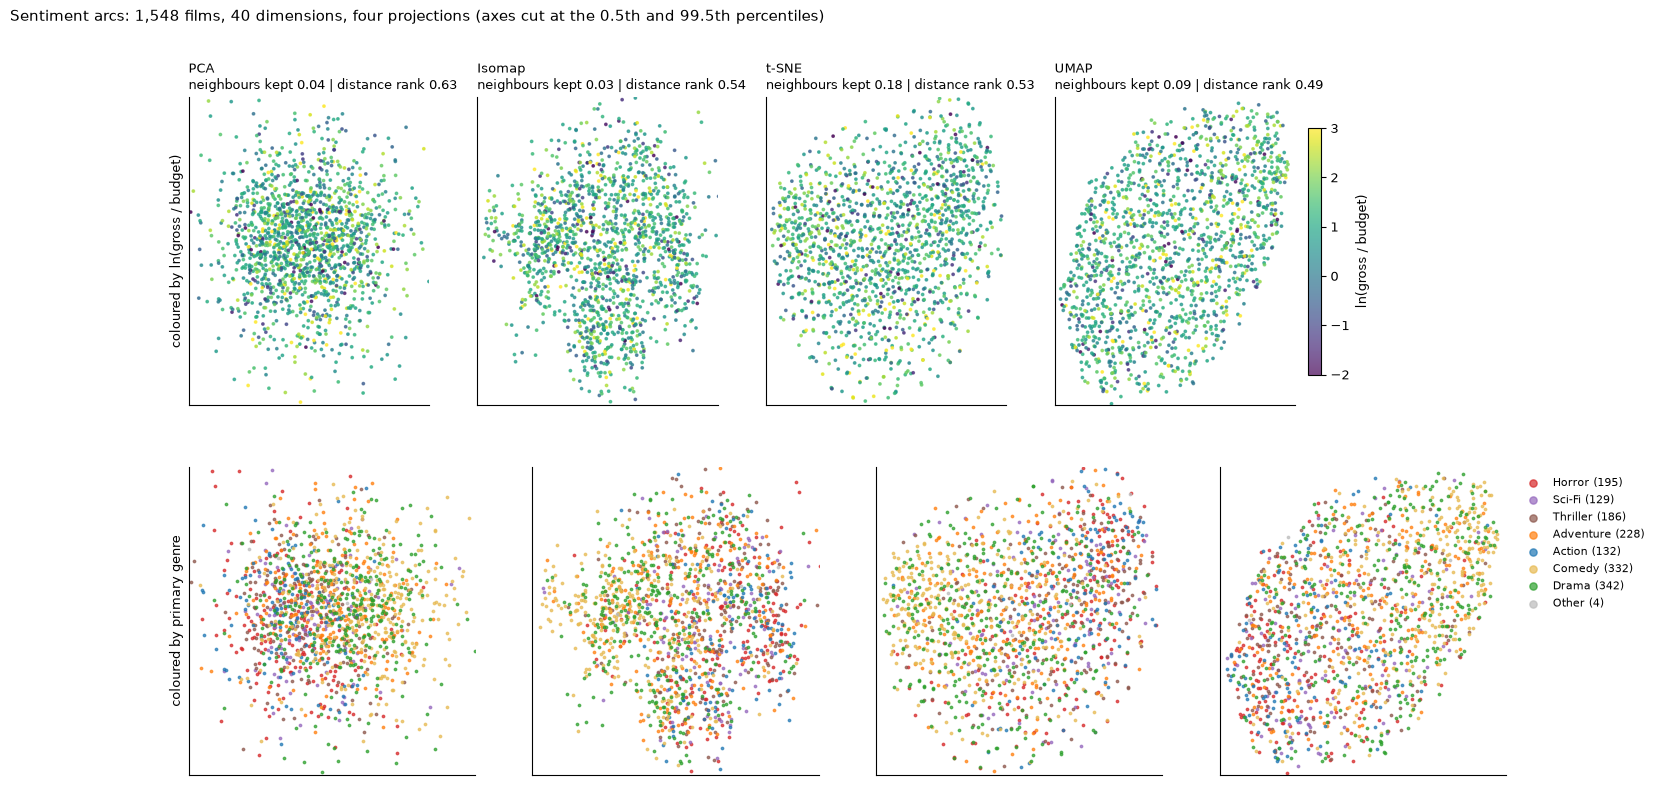

chance level for neighbours kept: 0.0065; profit smoothness in the full space: -0.031 (shuffled outcomes, 95% range -0.066 to +0.045)
net of budget, year and genre: full space -0.036 (shuffled, 95% range -0.051 to +0.050)
        neighbours kept  distance rank  profit smoothness  net smoothness
method                                                                   
PCA               0.036          0.635             -0.005          -0.000
Isomap            0.030          0.540             -0.055          -0.062
t-SNE             0.176          0.529              0.025           0.027
UMAP              0.087          0.487              0.014          -0.004


In [10]:
run("Sentiment arcs")

## 9. All spaces side by side

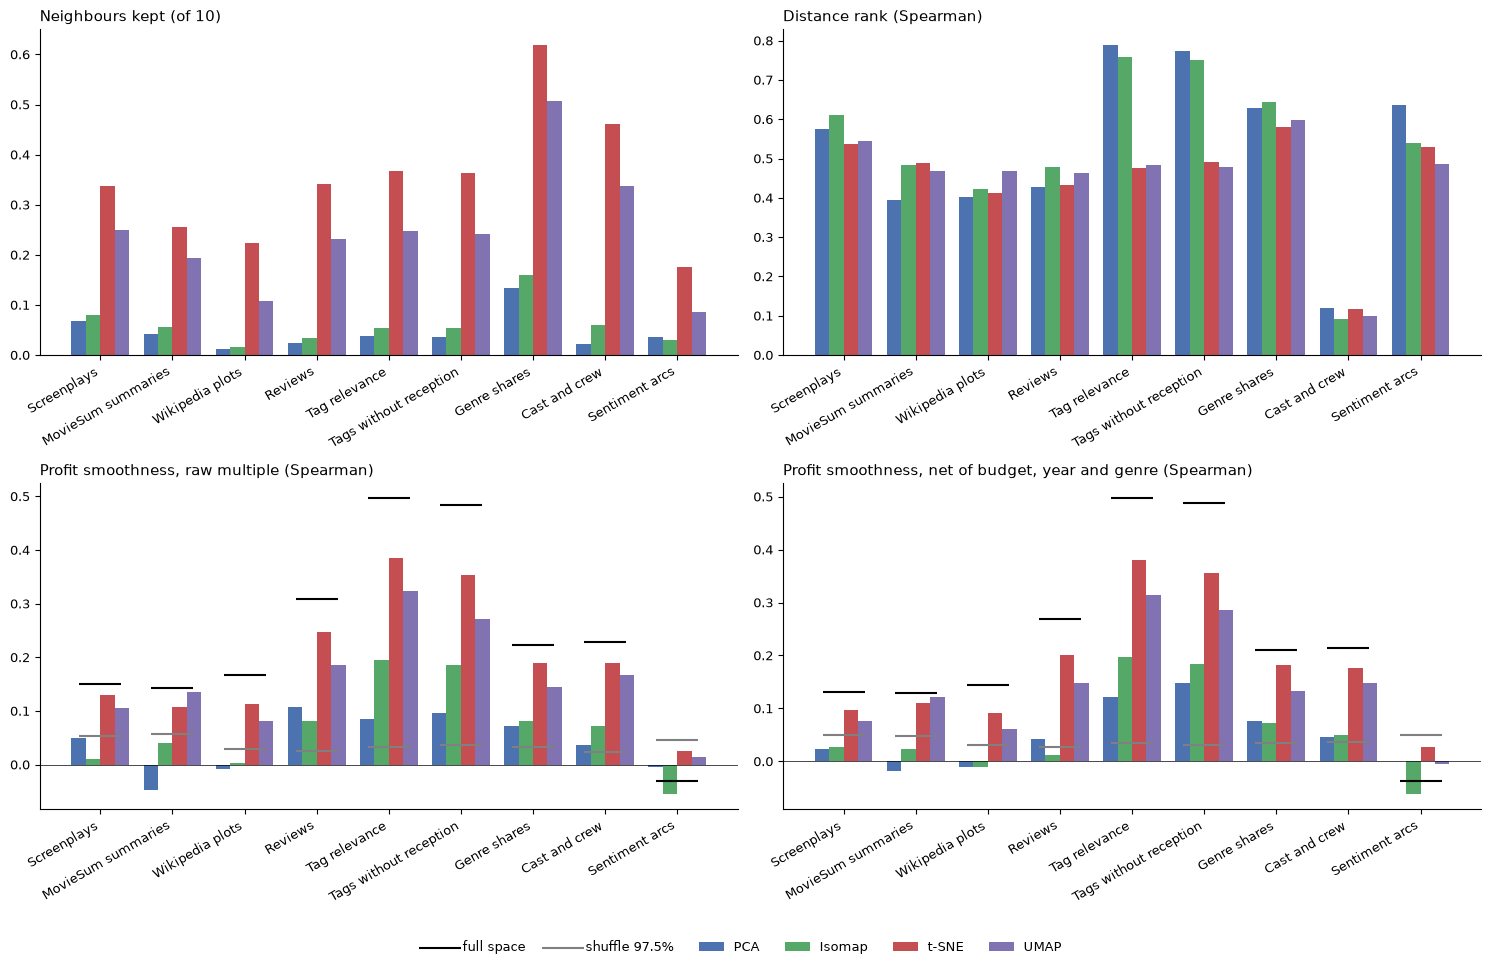

                               films  dims  neighbours kept  distance rank  profit smoothness  full-space smoothness  null 97.5%  net smoothness  full-space net smoothness  net null 97.5%
space                  method                                                                                                                                                              
Screenplays            PCA      1630   384            0.068          0.575              0.049                  0.151       0.054           0.024                      0.130           0.050
                       Isomap   1630   384            0.079          0.611              0.011                  0.151       0.054           0.028                      0.130           0.050
                       t-SNE    1630   384            0.338          0.537              0.130                  0.151       0.054           0.098                      0.130           0.050
                       UMAP     1630   384            0.249 

In [11]:
R = pd.concat(results, ignore_index=True)
order = R.drop_duplicates("space").space.tolist()
methods = ["PCA", "Isomap", "t-SNE", "UMAP"]
colours = dict(zip(methods, ["#4c72b0", "#55a868", "#c44e52", "#8172b2"]))
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
axes = axes.ravel()
panels = [("neighbours kept", None, None), ("distance rank", None, None),
          ("profit smoothness", "full-space smoothness", "null 97.5%"),
          ("net smoothness", "full-space net smoothness", "net null 97.5%")]
x = np.arange(len(order))
for i, mth in enumerate(methods):
    r = R[R.method == mth].set_index("space").loc[order]
    for ax, (col, _, _) in zip(axes, panels):
        ax.bar(x + (i - 1.5) * 0.2, r[col], 0.2, color=colours[mth], label=mth)
first = R.drop_duplicates("space").set_index("space").loc[order]
for ax, (col, full_col, null_col) in zip(axes, panels):
    if full_col:
        ax.scatter(x, first[full_col], marker="_", s=900, color="black", zorder=3, label="full space")
        ax.scatter(x, first[null_col], marker="_", s=900, color="grey", zorder=3, label="shuffle 97.5%")
titles = ["Neighbours kept (of 10)", "Distance rank (Spearman)", "Profit smoothness, raw multiple (Spearman)",
          "Profit smoothness, net of budget, year and genre (Spearman)"]
for ax, t in zip(axes, titles):
    ax.set_xticks(x, order, rotation=30, ha="right"); ax.set_title(t, loc="left"); ax.axhline(0, color="black", lw=0.5)
fig.legend(*axes[2].get_legend_handles_labels(), loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()
cols = ["films", "dims", "neighbours kept", "distance rank", "profit smoothness", "full-space smoothness", "null 97.5%",
        "net smoothness", "full-space net smoothness", "net null 97.5%"]
print(R.set_index(["space", "method"])[cols].round(3).to_string())

# Saved for the explorer's Embedding maps page and notebooks/embedding_map_checks.ipynb. The coordinates hold titles,
# so they stay in data/raw; the scores are numbers only and are also kept in analysis/embedding_maps/.
pd.concat(coords, ignore_index=True).to_csv(F / "embedding_maps.csv", index=False)
R.to_csv(F / "embedding_map_scores.csv", index=False)
Path("../analysis/embedding_maps").mkdir(exist_ok=True)
R.to_csv("../analysis/embedding_maps/scores.csv", index=False)

## 10. What the maps show and what they hide

**Which method to use.** t-SNE keeps the most of each film's neighbourhood in every space (18 to 62% of the 10
nearest films), then UMAP (9 to 51%). PCA and Isomap keep 1 to 16%. In exchange PCA and Isomap keep distance ranks
better on the two tag spaces (0.75 to 0.79 against 0.48 to 0.49). Cast and crew is the odd one: no map keeps its
distances (0.09 to 0.12), because most pairs of films share nobody and sit at about the same distance. Elsewhere the
four methods are within 0.15 of each other on distance rank. For "which films are like this one" read t-SNE or UMAP.
For "how far apart are two groups" read PCA, and don't read gaps between t-SNE or UMAP clusters at all.

**What the maps organise films by.** On the tag and genre-share spaces, t-SNE and UMAP split off horror, comedy,
adventure and sci-fi as separate islands (bottom rows of sections 5, 5b and 6). The text spaces show the same order
more weakly. Genre is the main structure each map finds, not profit.

**Profit, raw.** In eight spaces a film's multiple goes with its neighbours' more than chance allows: full-space
smoothness is 0.143 to 0.496, against shuffle 97.5th percentiles of 0.024 to 0.056. Sentiment arcs show none
(-0.031, inside the shuffle range). Every map shows less than its space really has. The PCA maps of screenplays,
summaries and Wikipedia plots show almost none (-0.047 to 0.049), and t-SNE or UMAP come closest.

**Profit, net of budget, year and genre (the narrower question).** It barely changes. Budget, year, year squared and
20 genre dummies explain only R2 = 0.072 of ln(multiple), so the residual is mostly the raw multiple. Net full-space
smoothness is 0.129 to 0.497 in the eight spaces, against 0.143 to 0.496 raw. Reviews drop the most (0.309 to
0.270), and the tag space not at all (0.496 to 0.497). So the neighbourhood structure isn't mainly cheap genre films
sitting together, at least as far as a linear control for genre and budget can tell. A finer control (genre by
budget, franchise) could still take more out.

**Tags without reception (the narrower tag space).** Taking out the 106 tags that judge quality, record an award or
list, or mark cult status lowers full-space smoothness only from 0.496 to 0.485 (net 0.497 to 0.489). So the tag
space's profit structure isn't carried by the obvious reception tags. That doesn't clear it of leakage: every Tag
Genome score is predicted from what viewers tagged, rated and wrote after release.

**Cast and crew.** Films made by the same people share profit (0.229 raw, 0.214 net), about as much as genre shares
do, and the space is built only from who made the film. But the space also sorts films strongly by era (year
smoothness 0.689 in `embedding_map_checks.ipynb`), and a team hired again after a hit is the outcome feeding back.
Before reading it as a predictor, the neighbours should be limited to earlier films.

**Which space holds the most.** The two tag spaces (0.485 to 0.497) and reviews (0.270 to 0.309) hold the most profit
structure, and all three are built from what viewers did after release. Cast and crew (0.214 to 0.229) and genre
shares (0.210 to 0.222) come next. The texts that describe the film itself (Wikipedia plots, screenplays, MovieSum
summaries) are close together (0.129 to 0.168). Smoothness isn't a prediction test. The cross-validated test is step 3
of analysis/embeddings.